# VoCE demo

This notebook shows how to use **VoCE** (Voronoi Consistency Ensemble) for multi-view anomaly detection:

1. a two-view toy data set with the three types of multi-view anomalies,
2. fitting VoCE and reading its two components, the transfer score $T$ and the inconsistency $I$,
3. what happens inside one round: shared anchors, Voronoi cells and the consistency check,
4. the effect of the number of anchors $\psi$,
5. a real data set from the paper (runs only if the raw data are in `datasets/`).

VoCE needs no training and runs in time linear in the number of samples. Its only parameters are the number of anchors per round $\psi$ (default 16) and the number of rounds $t$ (default 200).

In [1]:
import os, sys
sys.path.insert(0, os.path.abspath('.'))          # run the notebook from the repository root
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score
from voce import VoCE
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})

## 1. A toy data set with three anomaly types

Two views, three normal groups. A normal sample keeps its group and its position inside the group in both views, so its local neighborhood is consistent across views. We then create
* **attribute anomalies**: far from all normal groups in every view (uniform noise),
* **class anomalies**: normal in each view, but view 2 is taken from a sample of another group,
* **class-attribute anomalies**: view 1 from another group, view 2 replaced by noise.

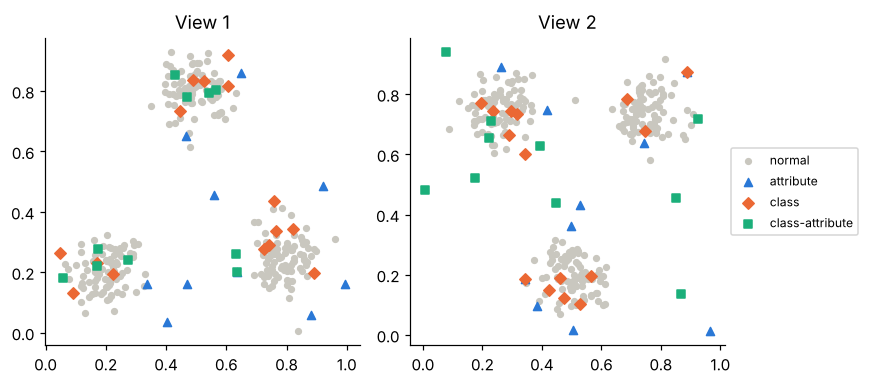

300 samples, 35 anomalies


In [2]:
rng = np.random.default_rng(0)
centers1 = np.array([[0.2, 0.2], [0.8, 0.25], [0.5, 0.8]])
centers2 = np.array([[0.25, 0.75], [0.75, 0.75], [0.5, 0.2]])
n_per = 100
g = np.repeat(np.arange(3), n_per)
z = 0.06 * rng.standard_normal((len(g), 2))       # a sample's position inside its group, shared by both views
X1 = centers1[g] + z + 0.01 * rng.standard_normal((len(g), 2))
X2 = centers2[g] + z[:, ::-1] + 0.01 * rng.standard_normal((len(g), 2))
types = np.array(['normal'] * len(g), dtype=object)

idx = rng.permutation(len(g))
att, cls, ca = idx[:10], idx[10:25], idx[25:35]
X1[att] = rng.uniform(0, 1, (len(att), 2)); X2[att] = rng.uniform(0, 1, (len(att), 2)); types[att] = 'attribute'
for i in cls:                                     # view 2 from a sample of another group
    j = rng.choice(np.where(g != g[i])[0]); X2[i] = X2[j].copy()
types[cls] = 'class'
for i in ca:                                      # view 1 from another group, view 2 noise
    j = rng.choice(np.where(g != g[i])[0]); X1[i] = X1[j].copy()
X2[ca] = rng.uniform(0, 1, (len(ca), 2)); types[ca] = 'class-attribute'
y = (types != 'normal').astype(int)
views = [X1, X2]

style = {'normal': ('#c9c7bf', 'o'), 'attribute': ('#2a78d6', '^'), 'class': ('#eb6834', 'D'), 'class-attribute': ('#1baf7a', 's')}
fig, axs = plt.subplots(1, 2, figsize=(8, 3.6))
for ax, X, t in zip(axs, views, ['View 1', 'View 2']):
    for k, (c, m) in style.items():
        s = types == k
        ax.scatter(X[s, 0], X[s, 1], c=c, marker=m, s=14 if k == 'normal' else 28, label=k, zorder=1 if k == 'normal' else 3)
    ax.set_title(t)
axs[1].legend(fontsize=8, loc='center left', bbox_to_anchor=(1, 0.5))
plt.tight_layout(); plt.show()
print(f'{len(y)} samples, {y.sum()} anomalies')

## 2. Fit VoCE

`fit` samples the anchors of every round and records the statistics of every Voronoi cell; `decision_function` returns the score (higher = more anomalous). `decision_components` returns the two parts, whose sum is the score:

* $I$: the fraction of rounds in which the sample falls into the cells of **different** anchors in different views (Shared-Anchor Voronoi Consistency),
* $T$: how far the sample lies from the anchors of its cells, relative to the size of the cells, evaluated across views (Cell-Normalized Transfer).

In [3]:
model = VoCE(psi=16, t=200, random_state=0).fit(views)
T, I = model.decision_components(views)
score = T + I                                      # identical to model.decision_function(views)
print(f'AUC-ROC {roc_auc_score(y, score):.3f}   AUC-PR {average_precision_score(y, score):.3f}')
print()
print(f'{"type":18s}{"T":>8s}{"I":>8s}{"T+I":>8s}   (AUC-ROC of each type against the normal samples)')
for k in ['attribute', 'class', 'class-attribute']:
    s = (types == k) | (types == 'normal'); yy = (types[s] == k).astype(int)
    print(f'{k:18s}{roc_auc_score(yy, T[s]):8.3f}{roc_auc_score(yy, I[s]):8.3f}{roc_auc_score(yy, score[s]):8.3f}')

AUC-ROC 0.997   AUC-PR 0.982

type                     T       I     T+I   (AUC-ROC of each type against the normal samples)
attribute            0.990   0.926   0.992
class                1.000   1.000   1.000
class-attribute      0.991   0.960   0.998


On this easy toy data both components already separate most anomalies. The scatter below places every sample by its mean $T$ and mean $I$: class anomalies are pushed up along $I$, while attribute anomalies are pushed right along $T$ and can still be consistent, which is why $I$ alone misses part of them. On the real data of the paper, class anomalies are separated better by $I$ and attribute anomalies better by $T$, and only the sum is strong on all three types. The level sets of the score $T+I$ are diagonal lines.

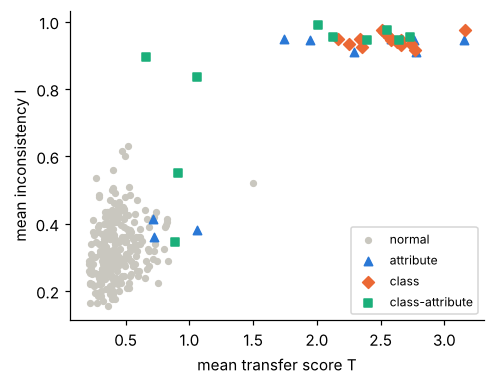

In [4]:
fig, ax = plt.subplots(figsize=(4.6, 3.6))
for k, (c, m) in style.items():
    s = types == k
    ax.scatter(T[s], I[s], c=c, marker=m, s=14 if k == 'normal' else 30, label=k, zorder=1 if k == 'normal' else 3)
ax.set_xlabel('mean transfer score T'); ax.set_ylabel('mean inconsistency I')
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. Inside one round

In each round the same $\psi$ samples are anchors in **all** views, and every view is split into the Voronoi cells of these anchors. A sample is consistent in the round if its nearest anchor is the same in every view. `round_components` returns, for one round, the transfer score $T_r$, the consistency $C_r$ (so $I_r = 1 - C_r$), the tie sets and the single-view scores.

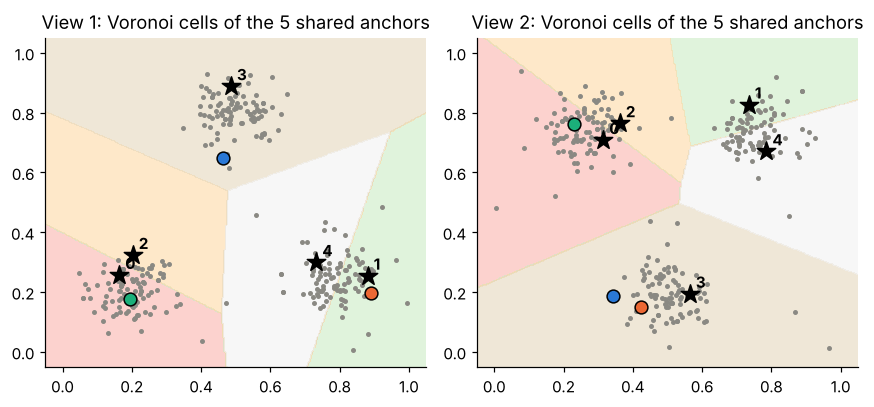

class anomaly (orange)     nearest anchor per view [[1], [3]]   consistent False   T_r = 2.95   round score = 3.95
attribute anomaly (blue)   nearest anchor per view [[3], [3]]   consistent True   T_r = 0.88   round score = 0.88
normal sample (green)      nearest anchor per view [[0], [0]]   consistent True   T_r = 0.26   round score = 0.26


In [5]:
small = VoCE(psi=5, t=1, random_state=11).fit(views)
anchors = small.indices[0]
Tr, Cr, A, S = small.round_components(views, 0)

xs = np.linspace(-0.05, 1.05, 300); gx, gy = np.meshgrid(xs, xs); grid = np.c_[gx.ravel(), gy.ravel()]
fig, axs = plt.subplots(1, 2, figsize=(8, 3.8))
show = [cls[0], att[4], 0]                        # a class anomaly, an attribute anomaly and a normal sample
for v, ax in enumerate(axs):
    Av = views[v][anchors]
    cell = ((grid[:, None, :] - Av[None]) ** 2).sum(-1).argmin(1).reshape(gx.shape)
    ax.contourf(gx, gy, cell, levels=np.arange(-0.5, 5), cmap='Pastel1', alpha=0.6)
    ax.scatter(views[v][:, 0], views[v][:, 1], c='#8a8983', s=5)
    for j, a in enumerate(Av):
        ax.scatter(*a, c='k', marker='*', s=160); ax.annotate(str(j), a, xytext=(4, 4), textcoords='offset points', fontsize=10, weight='bold')
    for i, c in zip(show, ['#eb6834', '#2a78d6', '#1baf7a']):
        ax.scatter(*views[v][i], c=c, s=70, edgecolors='k', zorder=5)
    ax.set_title(f'View {v + 1}: Voronoi cells of the 5 shared anchors'); ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
plt.tight_layout(); plt.show()

for i, name in zip(show, ['class anomaly (orange)', 'attribute anomaly (blue)', 'normal sample (green)']):
    cells_ = [[int(j) for j in np.where(A[v][i])[0]] for v in range(2)]
    print(f'{name:26s} nearest anchor per view {cells_}   consistent {bool(Cr[i])}   T_r = {Tr[i]:.2f}   round score = {Tr[i] + (not Cr[i]):.2f}')

The class anomaly falls into the cells of different anchors in the two views, so it is inconsistent ($I_r = 1$). The attribute anomaly is consistent but lies far from its anchor relative to the size of its cell, so its $T_r$ is large. The normal sample is consistent and close to its anchor.

Within every round, a consistent sample scores at most 1 and an inconsistent sample at least 1, so every inconsistent sample ranks at or above every consistent one; weight 1 on $I$ is the smallest weight with this property. Averaging over many rounds with independently drawn anchors gives the final score.

In [6]:
Ts, Cs = [], []
for it in range(model.t):
    Tr, Cr, _, _ = model.round_components(views, it)
    Ts.append(Tr); Cs.append(Cr)
Ts, Cs = np.array(Ts), np.array(Cs)
print('largest round score of a consistent sample :', round(Ts[Cs].max(), 3))
print('smallest round score of an inconsistent one:', round((Ts[~Cs] + 1).min(), 3))
print('mean over rounds equals the VoCE score     :', np.allclose((Ts + ~Cs).mean(0), score))

largest round score of a consistent sample : 1.0
smallest round score of an inconsistent one: 1.048
mean over rounds equals the VoCE score     : True


## 4. Number of anchors $\psi$

$\psi$ sets how many cells cover the data; the size of each cell still follows the local density, so the result is stable over a wide range.

In [7]:
for psi in [2, 4, 8, 16, 32, 64]:
    s = VoCE(psi=psi, t=200, random_state=0).fit(views).decision_function(views)
    print(f'psi = {psi:3d}   AUC-ROC {roc_auc_score(y, s):.3f}   AUC-PR {average_precision_score(y, s):.3f}')

psi =   2   AUC-ROC 0.974   AUC-PR 0.939
psi =   4   AUC-ROC 0.996   AUC-PR 0.977


psi =   8   AUC-ROC 0.997   AUC-PR 0.984


psi =  16   AUC-ROC 0.997   AUC-PR 0.982


psi =  32   AUC-ROC 0.997   AUC-PR 0.982


psi =  64   AUC-ROC 0.981   AUC-PR 0.951


## 5. A dataset from the paper

`voce.data.prepare(name, ratio, seed)` reproduces the data of the paper: min-max scaling, the anomaly injection of ECMOD, and for BBCSport and Reuters (`bbcsport_tn`, `reuters_tn`) the per-sample z-score. The raw files go into `datasets/` (see the README). The cell below runs WDBC with ratio 555 over the 10 data seeds at the $\psi$ selected in the paper and prints the entry of the main results table; `python reproduce.py` does the same for all 30 settings.

In [8]:
from voce.data import prepare

ds, ratio, psi = 'wdbc', '555', 8                   # psi selected for this setting in the paper
if os.path.exists('datasets/wdbc.data'):
    roc, pr = [], []
    for seed in range(1, 11):
        X, y_real = prepare(ds, ratio, seed)
        s = VoCE(psi=psi, t=200, random_state=1000 + seed).fit(X).decision_function(X)   # seed rule of the paper
        roc.append(roc_auc_score(y_real, s)); pr.append(average_precision_score(y_real, s))
    print(f'{ds} {ratio}: {len(y_real)} samples, views {[v.shape[1] for v in X]}, {y_real.sum()} anomalies')
    print(f'mean over 10 seeds   AUC-ROC {np.mean(roc):.3f}   AUC-PR {np.mean(pr):.3f}')
    print('paper                AUC-ROC 0.981   AUC-PR 0.929')
else:
    print('put wdbc.data into datasets/ to run this cell')

wdbc 555: 569 samples, views [10, 10, 10], 84 anomalies
mean over 10 seeds   AUC-ROC 0.981   AUC-PR 0.929
paper                AUC-ROC 0.981   AUC-PR 0.929
